In [1]:
import sys
import torch

print("=== ENVIRONMENT CHECK ===")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)

    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(gpu.total_memory / 1024**3, 2), "GB")
    print("CUDA Version:", torch.version.cuda)
else:
    print("GPU not detected. Enable GPU runtime in Colab.")

=== ENVIRONMENT CHECK ===
Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB
CUDA Version: 13.0


In [5]:
%pip install -q jedi
%pip install -q "huggingface-hub>=1.31.0,<2.0"
%pip install -q -U transformers accelerate safetensors

import transformers
import accelerate
import huggingface_hub

print("=== LIBRARY VERSIONS ===")
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("\n Inference libraries installed")

=== LIBRARY VERSIONS ===
Transformers: 5.23.0
Accelerate: 1.15.0
Hugging Face Hub: 2.4.0

✅ Inference libraries installed


## Load Qwen2.5-0.5B-Instruct on the *GPU*

In [6]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

print("=== LOADING MODEL ===")

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Load model in FP16
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16
).to("cuda")

# Enable evaluation mode
model.eval()

# Display model information
total_params = sum(p.numel() for p in model.parameters())

gpu_memory = torch.cuda.memory_allocated() / 1024**3

print("\n=== MODEL INFORMATION ===")
print("Model:", MODEL_ID)
print("Architecture:", model.config.model_type)
print("Parameters:", f"{total_params:,}")
print("Precision:", next(model.parameters()).dtype)
print("Device:", next(model.parameters()).device)
print("Default KV Cache:", model.config.use_cache)
print("Allocated GPU Memory:", round(gpu_memory, 3), "GB")

print("\n Model loaded successfully")

=== LOADING MODEL ===


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


=== MODEL INFORMATION ===
Model: Qwen/Qwen2.5-0.5B-Instruct
Architecture: qwen2
Parameters: 494,032,768
Precision: torch.float16
Device: cuda:0
Default KV Cache: True
Allocated GPU Memory: 0.928 GB

✅ Model loaded successfully


## Generate text and measure inference time

In [7]:
import time
import torch

messages = [
    {
        "role": "user",
        "content": "Explain how solar panels generate electricity in simple terms."
    }
]

# Convert the conversation into model tokens
inputs = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt"
).to("cuda")

input_tokens = inputs["input_ids"].shape[-1]

# Synchronize GPU before measuring
torch.cuda.synchronize()
start = time.perf_counter()

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False,
        use_cache=True,
        pad_token_id=tokenizer.eos_token_id
    )

# Synchronize GPU after generation
torch.cuda.synchronize()
elapsed = time.perf_counter() - start

# Count newly generated tokens
generated_tokens = outputs.shape[-1] - input_tokens

# Decode only the generated response
response = tokenizer.decode(
    outputs[0][input_tokens:],
    skip_special_tokens=True
)

print("=== FIRST INFERENCE ===")
print("Input tokens:", input_tokens)
print("Generated tokens:", generated_tokens)
print("Total inference time:", round(elapsed, 3), "seconds")
print(
    "Generation throughput:",
    round(generated_tokens / elapsed, 2),
    "tokens/second"
)

print("\n=== MODEL RESPONSE ===")
print(response)

=== FIRST INFERENCE ===
Input tokens: 40
Generated tokens: 100
Total inference time: 8.046 seconds
Generation throughput: 12.43 tokens/second

=== MODEL RESPONSE ===
Solar panels work by converting sunlight into electrical energy through a process called photovoltaic (PV) effect. Here's a simplified explanation of the basic principle:

1. **Sunlight Absorption**: Solar panels are made up of thin silicon or other semiconductor materials that can absorb light from the sun.

2. **Photovoltaic Effect**: When sunlight hits these materials, it excites electrons within them. These electrons have enough energy to move freely and flow through the material, creating an electric current.

3


## Observe how the KV cache grows

In [9]:
import torch

# Use the same tokenized prompt from Step 4
model.eval()

with torch.inference_mode():

    # Process the prompt (prefill)
    prefill = model(
        **inputs,
        use_cache=True
    )

    cache = prefill.past_key_values

    print("=== PREFILL ===")
    print("Input tokens:", inputs["input_ids"].shape[-1])
    print("Cache type:", type(cache).__name__)
    print("Cached positions:", cache.get_seq_length())

    # Predict the next token
    next_token = prefill.logits[:, -1, :].argmax(
        dim=-1,
        keepdim=True
    )

    print("\nNext predicted token:",
          repr(tokenizer.decode(next_token[0])))

    # Process that one new token using the existing cache
    decode = model(
        input_ids=next_token,
        attention_mask=torch.ones(
            (1, inputs["input_ids"].shape[-1] + 1),
            dtype=torch.long,
            device=next_token.device
        ),
        past_key_values=cache,
        use_cache=True
    )

    print("\n=== ONE DECODE STEP ===")
    print("New input tokens processed:", next_token.shape[-1])
    print("Cached positions after decode:",
          decode.past_key_values.get_seq_length())

print("\n Prefill and one cached decoding step completed")

=== PREFILL ===
Input tokens: 40
Cache type: DynamicCache
Cached positions: 40

Next predicted token: 'Solar'

=== ONE DECODE STEP ===
New input tokens processed: 1
Cached positions after decode: 41

 Prefill and one cached decoding step completed


## What happens when we disable KV caching?


In [10]:
import torch

model.eval()

# Use the same original 40-token prompt
original_ids = inputs["input_ids"]
original_mask = inputs["attention_mask"]

with torch.inference_mode():

    # First forward pass: process the original prompt
    first_pass = model(
        input_ids=original_ids,
        attention_mask=original_mask,
        use_cache=False
    )

    first_token = first_pass.logits[:, -1, :].argmax(
        dim=-1,
        keepdim=True
    )

    # Append the predicted token to the full sequence
    extended_ids = torch.cat(
        [original_ids, first_token],
        dim=-1
    )

    extended_mask = torch.ones_like(extended_ids)

    # Second forward pass: process ALL tokens again
    second_pass = model(
        input_ids=extended_ids,
        attention_mask=extended_mask,
        use_cache=False
    )

print("=== KV CACHE DISABLED ===")
print("Original prompt tokens:", original_ids.shape[-1])
print("First forward pass tokens:", original_ids.shape[-1])
print("Second forward pass tokens:", extended_ids.shape[-1])

print("\nCache returned:", second_pass.past_key_values)

print("\nFirst generated token:",
      repr(tokenizer.decode(first_token[0])))

print("\n=== COMPARISON ===")
print("Cache ON  - second pass processes: 1 token")
print("Cache OFF - second pass processes:",
      extended_ids.shape[-1], "tokens")

=== KV CACHE DISABLED ===
Original prompt tokens: 40
First forward pass tokens: 40
Second forward pass tokens: 41

Cache returned: None

First generated token: 'Solar'

=== COMPARISON ===
Cache ON  - second pass processes: 1 token
Cache OFF - second pass processes: 41 tokens


## Benchmark KV Cache ON vs OFF

In [11]:
import time
import statistics
import torch

model.eval()

MAX_NEW_TOKENS = 64
WARMUP_RUNS = 2
MEASURED_RUNS = 3

def benchmark_cache(use_cache):
    timings = []
    token_counts = []

    for run in range(WARMUP_RUNS + MEASURED_RUNS):

        # Wait for previous GPU operations to finish
        torch.cuda.synchronize()

        start = time.perf_counter()

        with torch.inference_mode():
            output = model.generate(
                **inputs,
                max_new_tokens=MAX_NEW_TOKENS,
                min_new_tokens=MAX_NEW_TOKENS,
                do_sample=False,
                use_cache=use_cache,
                pad_token_id=tokenizer.eos_token_id
            )

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        generated = (
            output.shape[-1] - inputs["input_ids"].shape[-1]
        )

        if run >= WARMUP_RUNS:
            timings.append(elapsed)
            token_counts.append(generated)

    return {
        "median_latency": statistics.median(timings),
        "median_tokens_per_second": statistics.median(
            tokens / seconds
            for tokens, seconds in zip(token_counts, timings)
        ),
        "timings": timings,
        "generated_tokens": token_counts
    }

# Alternate configurations to reduce systematic ordering effects.
# Warm-up calls are performed within each benchmark.
cache_on = benchmark_cache(True)
cache_off = benchmark_cache(False)

print("=== KV CACHE BENCHMARK ===")
print("Model: Qwen2.5-0.5B-Instruct")
print("GPU: Tesla T4")
print("Input tokens:", inputs["input_ids"].shape[-1])
print("Target generated tokens:", MAX_NEW_TOKENS)

print("\nKV CACHE ON")
print("Run times:", [round(t, 3) for t in cache_on["timings"]])
print("Generated tokens:", cache_on["generated_tokens"])
print("Median latency:",
      round(cache_on["median_latency"], 3), "s")
print("Throughput:",
      round(cache_on["median_tokens_per_second"], 2),
      "tokens/s")

print("\nKV CACHE OFF")
print("Run times:", [round(t, 3) for t in cache_off["timings"]])
print("Generated tokens:", cache_off["generated_tokens"])
print("Median latency:",
      round(cache_off["median_latency"], 3), "s")
print("Throughput:",
      round(cache_off["median_tokens_per_second"], 2),
      "tokens/s")

speedup = (
    cache_off["median_latency"] /
    cache_on["median_latency"]
)

print("\n=== RESULT ===")
print("KV caching speedup:", round(speedup, 2), "x")

=== KV CACHE BENCHMARK ===
Model: Qwen2.5-0.5B-Instruct
GPU: Tesla T4
Input tokens: 40
Target generated tokens: 64

KV CACHE ON
Run times: [2.036, 1.657, 1.695]
Generated tokens: [64, 64, 64]
Median latency: 1.695 s
Throughput: 37.76 tokens/s

KV CACHE OFF
Run times: [1.843, 2.075, 1.95]
Generated tokens: [64, 64, 64]
Median latency: 1.95 s
Throughput: 32.82 tokens/s

=== RESULT ===
KV caching speedup: 1.15 x


## Test KV caching with a longer input prompt

In [12]:
import time
import statistics
import torch

# Build a longer prompt
paragraph = (
    "Machine learning systems process data using mathematical "
    "models. During inference, a trained model receives input "
    "tokens and predicts output tokens. Transformer models use "
    "attention mechanisms to understand relationships between "
    "tokens in the input sequence. "
)

long_text = paragraph * 30

long_messages = [
    {
        "role": "user",
        "content": (
            "Summarize the following technical explanation "
            "in simple terms:\n\n" + long_text
        )
    }
]

long_inputs = tokenizer.apply_chat_template(
    long_messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt"
).to("cuda")

# Keep the first 512 tokens for a controlled prompt length
long_inputs = {
    "input_ids": long_inputs["input_ids"][:, :512],
    "attention_mask": long_inputs["attention_mask"][:, :512]
}

print("=== LONG PROMPT ===")
print("Input tokens:", long_inputs["input_ids"].shape[-1])

def timed_generation(use_cache):
    torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        output = model.generate(
            **long_inputs,
            max_new_tokens=64,
            min_new_tokens=64,
            do_sample=False,
            use_cache=use_cache,
            pad_token_id=tokenizer.eos_token_id
        )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    return elapsed, output.shape[-1] - 512

# Warm up both paths
for setting in [True, False]:
    timed_generation(setting)

results = {True: [], False: []}

# Alternate order across repetitions
for order in [
    [True, False],
    [False, True],
    [True, False]
]:
    for setting in order:
        elapsed, count = timed_generation(setting)
        assert count == 64
        results[setting].append(elapsed)

on_median = statistics.median(results[True])
off_median = statistics.median(results[False])

print("\n=== LONG PROMPT BENCHMARK ===")

print("Cache ON timings:",
      [round(t, 3) for t in results[True]])

print("Cache OFF timings:",
      [round(t, 3) for t in results[False]])

print("\nMedian Cache ON:", round(on_median, 3), "s")
print("Median Cache OFF:", round(off_median, 3), "s")

print("Speedup:", round(off_median / on_median, 2), "x")

=== LONG PROMPT ===
Input tokens: 512

=== LONG PROMPT BENCHMARK ===
Cache ON timings: [1.84, 1.656, 1.655]
Cache OFF timings: [2.27, 2.308, 2.399]

Median Cache ON: 1.656 s
Median Cache OFF: 2.308 s
Speedup: 1.39 x


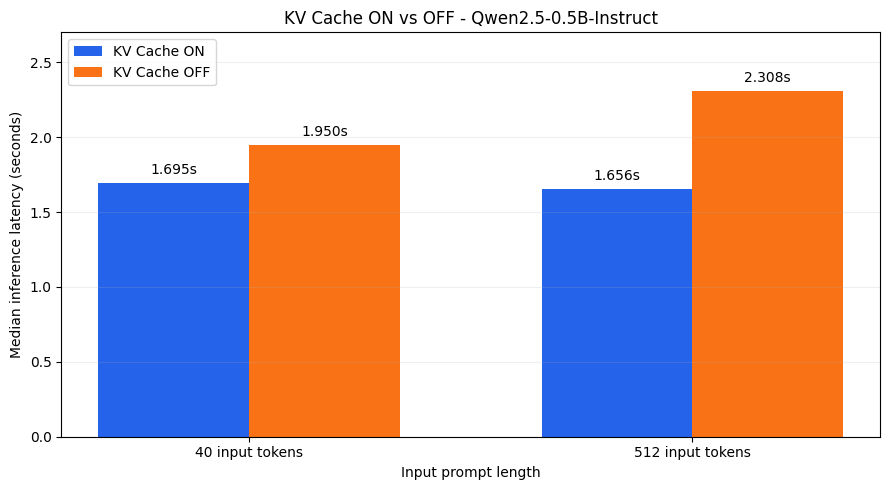

=== SPEEDUP ===
40 tokens: 1.15x faster with KV caching
512 tokens: 1.39x faster with KV caching


In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Actual measurements from Steps 7 and 8
prompt_lengths = [40, 512]

cache_on_latency = [1.695, 1.656]
cache_off_latency = [1.950, 2.308]

x = np.arange(len(prompt_lengths))
width = 0.34

fig, ax = plt.subplots(figsize=(9, 5))

bars_on = ax.bar(
    x - width / 2,
    cache_on_latency,
    width,
    label="KV Cache ON",
    color="#2563EB"
)

bars_off = ax.bar(
    x + width / 2,
    cache_off_latency,
    width,
    label="KV Cache OFF",
    color="#F97316"
)

for bars in [bars_on, bars_off]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.3f}s",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points"
        )

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{n} input tokens" for n in prompt_lengths]
)

ax.set_ylabel("Median inference latency (seconds)")
ax.set_xlabel("Input prompt length")
ax.set_title(
    "KV Cache ON vs OFF - Qwen2.5-0.5B-Instruct"
)
ax.legend()
ax.set_ylim(0, 2.7)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("=== SPEEDUP ===")

for length, on, off in zip(
    prompt_lengths,
    cache_on_latency,
    cache_off_latency
):
    print(
        f"{length} tokens: "
        f"{off / on:.2f}x faster with KV caching"
    )

## Measure GPU memory consumption

In [15]:
import torch
import gc
import statistics

model.eval()

def measure_gpu_memory(use_cache, prompt_inputs, max_tokens=64):

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

    # Memory allocated before inference
    baseline = torch.cuda.memory_allocated()

    # Reset peak memory tracking
    torch.cuda.reset_peak_memory_stats()

    with torch.inference_mode():
        output = model.generate(
            **prompt_inputs,
            max_new_tokens=max_tokens,
            min_new_tokens=max_tokens,
            do_sample=False,
            use_cache=use_cache,
            pad_token_id=tokenizer.eos_token_id
        )

    torch.cuda.synchronize()

    peak = torch.cuda.max_memory_allocated()

    result = {
        "baseline_mb": baseline / 1024**2,
        "peak_mb": peak / 1024**2,
        "additional_peak_mb": (peak - baseline) / 1024**2,
        "generated_tokens": (
            output.shape[-1] - prompt_inputs["input_ids"].shape[-1]
        )
    }

    del output
    return result


print("=== KV CACHE GPU MEMORY EXPERIMENT ===")
print("Model: Qwen2.5-0.5B-Instruct")
print("Input tokens:", long_inputs["input_ids"].shape[-1])
print("Generated tokens: 64")

memory_results = {}

for setting in [False, True]:
    label = "Cache ON" if setting else "Cache OFF"

    runs = [
        measure_gpu_memory(setting, long_inputs)
        for _ in range(3)
    ]

    memory_results[label] = runs

    print(f"\n{label}")

    print(
        "Median baseline memory:",
        round(statistics.median(
            r["baseline_mb"] for r in runs
        ), 2),
        "MB"
    )

    print(
        "Median peak memory:",
        round(statistics.median(
            r["peak_mb"] for r in runs
        ), 2),
        "MB"
    )

    print(
        "Median additional peak:",
        round(statistics.median(
            r["additional_peak_mb"] for r in runs
        ), 2),
        "MB"
    )

=== KV CACHE GPU MEMORY EXPERIMENT ===
Model: Qwen2.5-0.5B-Instruct
Input tokens: 512
Generated tokens: 64

Cache OFF
Median baseline memory: 994.97 MB
Median peak memory: 1016.23 MB
Median additional peak: 21.25 MB

Cache ON
Median baseline memory: 994.97 MB
Median peak memory: 1018.86 MB
Median additional peak: 23.88 MB


## GPU memory trade-off

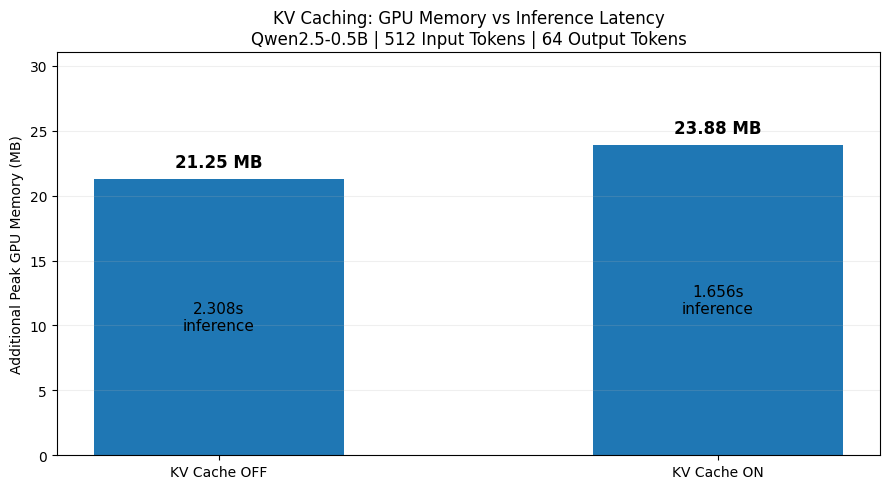

In [16]:
import matplotlib.pyplot as plt
import statistics

labels = ["KV Cache OFF", "KV Cache ON"]

additional_memory = [
    statistics.median(
        r["additional_peak_mb"]
        for r in memory_results["Cache OFF"]
    ),
    statistics.median(
        r["additional_peak_mb"]
        for r in memory_results["Cache ON"]
    )
]

latencies = [2.308, 1.656]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    labels,
    additional_memory,
    width=0.5
)

for bar, memory, latency in zip(
    bars, additional_memory, latencies
):
    ax.annotate(
        f"{memory:.2f} MB",
        (bar.get_x() + bar.get_width() / 2, memory),
        ha="center",
        va="bottom",
        xytext=(0, 6),
        textcoords="offset points",
        fontsize=12,
        fontweight="bold"
    )

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        memory / 2,
        f"{latency:.3f}s\ninference",
        ha="center",
        va="center",
        fontsize=11
    )

ax.set_title(
    "KV Caching: GPU Memory vs Inference Latency\n"
    "Qwen2.5-0.5B | 512 Input Tokens | 64 Output Tokens"
)

ax.set_ylabel("Additional Peak GPU Memory (MB)")
ax.set_ylim(0, max(additional_memory) * 1.3)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()